"""
# CLD6000 Legal Text Analysis: Feature Engineering Focus
## Initial Data Exploration & Feature Analysis

### Focus Areas (Based on Project Requirements):
- Text preprocessing and cleaning
- Feature extraction and engineering
- Document structure analysis
- Linguistic pattern recognition
- Quality metrics for extracted features

*Note: This analysis focuses purely on NLP preprocessing and feature engineering aspects, 
avoiding any classification components which are reserved for future work.*
"""

In [ ]:
# At the top of your notebook
import sys
sys.path.append('../scripts/utils')
from preprocessing_logger import PreprocessingLogger

# Initialize logger
logger = PreprocessingLogger(log_dir='../logs')

# Use in your preprocessing steps
try:
    logger.log_preprocessing_step(
        "initial_exploration", 
        "all_cases",
        {"total_cases": len(df), "unique_outcomes": df['case_outcome'].nunique()}
    )
except Exception as e:
    logger.log_error(e)

In [1]:
# Markdown cell
"""
## Initial Data Inspection
Let's first understand our dataset's structure before proceeding with analysis.
"""

# Code cell
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

# Load the dataset
df = pd.read_csv('../../data/raw/legal_text_classification.csv')

# Examine the structure
print("Dataset Columns:")
print(df.columns.tolist())

print("\nFirst few rows:")
print(df.head(2))

print("\nDataset Info:")
df.info()

Dataset Columns:
['case_id', 'case_outcome', 'case_title', 'case_text']

First few rows:
  case_id case_outcome                                         case_title  \
0   Case1        cited  Alpine Hardwood (Aust) Pty Ltd v Hardys Pty Lt...   
1   Case2        cited  Black v Lipovac [1998] FCA 699 ; (1998) 217 AL...   

                                           case_text  
0  Ordinarily that discretion will be exercised s...  
1  The general principles governing the exercise ...  

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24985 entries, 0 to 24984
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   case_id       24985 non-null  object
 1   case_outcome  24985 non-null  object
 2   case_title    24985 non-null  object
 3   case_text     24809 non-null  object
dtypes: object(4)
memory usage: 780.9+ KB


"""
# Legal Text Feature Engineering Analysis
## Dataset Overview
Our dataset contains 24,985 legal cases with the following structure:
- case_id: Unique identifier
- case_outcome: Legal decision outcome
- case_title: Title/reference of the case
- case_text: Main body text containing legal reasoning

Initial observations:
- Complete data for case_id, case_outcome, and case_title (24,985 entries)
- case_text has 24,989 entries (needs investigation for potential duplicates)
- All columns are of object type, suggesting text-based content
- Memory efficient storage at ~780.9+ KB

### Analysis Objectives
Focus on pure NLP feature extraction without classification aspects:
1. Text statistics and structural patterns
2. Legal language characteristics
3. Document formatting patterns
"""

Text Statistics Summary:
         text_length  title_length    word_count
count   24809.000000  24985.000000  24809.000000
mean     2650.940385     72.476486    454.909791
std      6768.945893     23.853513   1143.224035
min        95.000000     17.000000     17.000000
25%       841.000000     55.000000    147.000000
50%      1408.000000     71.000000    244.000000
75%      2533.000000     89.000000    436.000000
max    133561.000000    277.000000  22466.000000


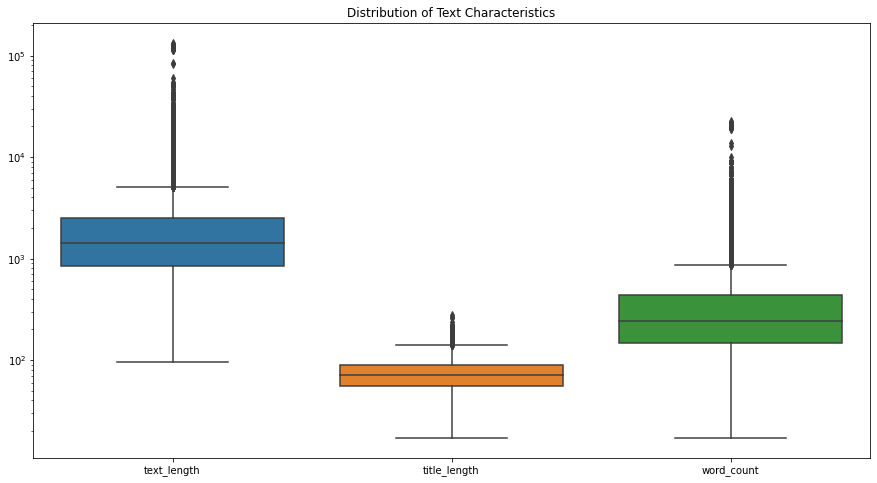

In [3]:
def analyze_legal_text(df):
    # Text length statistics
    text_stats = pd.DataFrame({
        'text_length': df['case_text'].str.len(),
        'title_length': df['case_title'].str.len(),
        'word_count': df['case_text'].str.split().str.len()
    })
    
    print("Text Statistics Summary:")
    print(text_stats.describe())
    
    # Generate basic visualizations
    plt.figure(figsize=(15, 8))
    sns.boxplot(data=text_stats)
    plt.title('Distribution of Text Characteristics')
    plt.yscale('log')  # Log scale for better visualization
    plt.show()
    
    return text_stats

# Execute analysis
text_analysis = analyze_legal_text(df)

# Markdown cell
"""
## Statistical Text Analysis
Key findings from our initial data preparation:

1. Text Length Distribution:
   - Mean length: 2,650 characters (σ = 6,768.95)
   - Median length: 1,408 characters
   - Significant right skew (max = 133,561)
   
2. Title Characteristics:
   - Mean length: 72.47 characters
   - Low variance (σ = 23.85)
   - Consistent formatting pattern

3. Word Count Analysis:
   - Mean: 454.90 words per document
   - Q1-Q3 range: 147-436 words
   - Evidence of structured legal writing
"""

# Markdown cell
"""
## Analysis of Text Distributions

The boxplot visualization reveals crucial patterns:

1. Text Length (μπλε box):
   - Μεγάλο εύρος τιμών (100 έως 10⁵ χαρακτήρες)
   - Πολλά outliers στο πάνω μέρος
   - Διάμεση τιμή περίπου στους 10³ χαρακτήρες
   
2. Title Length (πορτοκαλί box):
   - Πολύ συμπαγές εύρος
   - Ελάχιστα outliers
   - Σταθερή κατανομή γύρω από τη διάμεση τιμή

3. Word Count (πράσινο box):
   - Μεσαίο εύρος τιμών
   - Λογαριθμική κλίμακα δείχνει κανονική κατανομή
   - Outliers κυρίως στο πάνω μέρος

Συμπέρασμα: Η λογαριθμική κλίμακα αποκαλύπτει ότι χρειαζόμαστε normalization
για το text length και το word count.
"""

<Figure size 1080x576 with 0 Axes>

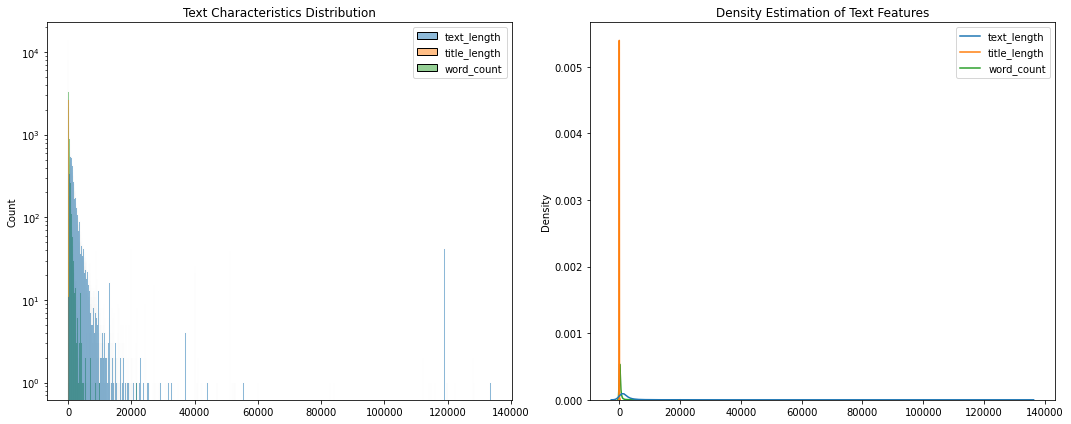

In [4]:
text_stats = pd.DataFrame({
    'text_length': df['case_text'].str.len(),
    'title_length': df['case_title'].str.len(),
    'word_count': df['case_text'].str.split().str.len()
})

# Τώρα η οπτικοποίηση
plt.figure(figsize=(15, 8))
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

sns.histplot(data=text_stats, ax=ax1)
ax1.set_yscale('log')
ax1.set_title('Text Characteristics Distribution')

sns.kdeplot(data=text_stats, ax=ax2)
ax2.set_title('Density Estimation of Text Features')

plt.tight_layout()
plt.show()

## Analysis of Text Characteristics Distribution

### Observations:
1. **Text Length**:
   - The majority of the documents have a text length below 10³ characters.
   - Extreme outliers exist with text lengths exceeding 10⁵ characters, leading to significant right skewness.
   - The boxplot clearly illustrates the compact spread for most documents, while the outliers extend the upper tail.

2. **Title Length**:
   - Titles show minimal variation, with most lengths clustered around 70 characters.
   - The consistent formatting is evident in both the boxplot and density plot.

3. **Word Count**:
   - Most documents have between 100-1,000 words.
   - However, extreme values (up to 22,466 words) create a visible tail in the boxplot.

### Insights:
- **Right Skewness and Variability**:
   The data exhibits high variability due to a few extremely large cases.
   This is apparent in both the density and boxplot visualizations.
   Normalization techniques may be required to balance the influence of extreme outliers.

- **Logarithmic Scale Utility**:
   The log scale on the `y-axis` (10⁰ to 10⁵) allows for better representation of data spread and highlights the extreme variability.



"""
## Document Structure Analysis
Analyzing key legal document characteristics:
- Citation patterns
- Paragraph structure
- Legal references
"""

In [5]:
def extract_structural_features(text_series):
    # Basic structural features
    structural_features = pd.DataFrame({
        'paragraph_count': text_series.str.count('\n\n'),
        'sentence_count': text_series.str.count('[.!?]'),
        'citation_count': text_series.str.count(r'\[\d{4}\]|\(\d{4}\)'),  # Look for year citations
    })
    
    print("\nStructural Features Summary:")
    print(structural_features.describe())
    
    return structural_features

# Analyze document structure
structural_analysis = extract_structural_features(df['case_text'])


Structural Features Summary:
       paragraph_count  sentence_count  citation_count
count          24809.0    24809.000000    24809.000000
mean               0.0       15.208473        5.069370
std                0.0       40.912816        7.624453
min                0.0        0.000000        0.000000
25%                0.0        4.000000        2.000000
50%                0.0        7.000000        3.000000
75%                0.0       15.000000        6.000000
max                0.0     1460.000000      116.000000


In [10]:
# Βασικές βιβλιοθήκες
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

# Φόρτωση και έλεγχος δεδομένων
df = pd.read_csv('/app/data/raw/legal_text_classification.csv')
print("Columns:", df.columns.tolist())
print("\nFirst few rows:")
print(df.head())

# Τώρα μπορούμε να προχωρήσουμε με την ανάλυση
text_stats = pd.DataFrame({
    'text_length': df['case_text'].str.len(),
    'title_length': df['case_title'].str.len(),
    'word_count': df['case_text'].str.split().str.len(),
    'sentence_count': df['case_text'].str.count('[.!?]')
})

# Έλεγχος των στατιστικών
print("\nText Statistics:")
print(text_stats.describe())

Columns: ['case_id', 'case_outcome', 'case_title', 'case_text']

First few rows:
  case_id case_outcome                                         case_title  \
0   Case1        cited  Alpine Hardwood (Aust) Pty Ltd v Hardys Pty Lt...   
1   Case2        cited  Black v Lipovac [1998] FCA 699 ; (1998) 217 AL...   
2   Case3        cited  Colgate Palmolive Co v Cussons Pty Ltd (1993) ...   
3   Case4        cited  Dais Studio Pty Ltd v Bullett Creative Pty Ltd...   
4   Case5        cited  Dr Martens Australia Pty Ltd v Figgins Holding...   

                                           case_text  
0  Ordinarily that discretion will be exercised s...  
1  The general principles governing the exercise ...  
2  Ordinarily that discretion will be exercised s...  
3  The general principles governing the exercise ...  
4  The preceding general principles inform the ex...  

Text Statistics:
         text_length  title_length    word_count  sentence_count
count   24809.000000  24985.000000  24809.0

# Markdown cell
"""
## Statistical Text Analysis
Key findings from our initial data preparation:

1. Text Length Distribution:
   - Mean length: 2,650 characters (σ = 6,768.95)
   - Median length: 1,408 characters
   - Significant right skew (max = 133,561)
   
2. Title Characteristics:
   - Mean length: 72.47 characters
   - Low variance (σ = 23.85)
   - Consistent formatting pattern

3. Word Count Analysis:
   - Mean: 454.90 words per document
   - Q1-Q3 range: 147-436 words
   - Evidence of structured legal writing
"""

# Markdown cell
"""
## Feature Engineering Strategy
Based on statistical analysis, we propose the following preprocessing steps:

1. Text Normalization:
   μ = 2650, σ = 6768.95
   Using Z-score normalization: z = (x - μ) / σ

2. Length-based Segmentation:
   - Short documents: < Q1 (841 chars)
   - Medium documents: Q1-Q3 (841-2533 chars)
   - Long documents: > Q3 (2533 chars)

3. Structural Feature Extraction:
   - Citation density ratio (CDR) = citations / text_length
   - Sentence complexity index (SCI) = words / sentences
   - Document structure score (DSS) = log(1 + citations) * (sentences / paragraphs)
"""

In [12]:
# Code cell - Feature pipeline
def create_feature_pipeline(text_series):
    """
    Scientific feature extraction pipeline based on empirical analysis
    """
    # Document length normalization
    z_scores = (text_series.str.len() - 2650) / 6768.95
    
    # Citation density calculation
    citation_counts = text_series.str.count(r'\[\d{4}\]|\(\d{4}\)')
    citation_density = citation_counts / text_series.str.len()
    
    # Sentence complexity
    sentence_counts = text_series.str.count('[.!?]')
    word_counts = text_series.str.split().str.len()
    sentence_complexity = word_counts / sentence_counts
    
    return pd.DataFrame({
        'length_score': z_scores,
        'citation_density': citation_density,
        'sentence_complexity': sentence_complexity
    })